# Boston Employee Earnings Analysis (2022-2024)
**Authors:** Dev Panchal, Om Patel  
**Course:** ALY 6140 - Python & Analytics  
**Date:** October 2025

## 1. Import Libraries and Custom Functions

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
import warnings
warnings.filterwarnings('ignore')

from capstone_group01 import load_and_combine_data, clean_employee_data, plot_feature_importance

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("✓ Libraries loaded successfully!")

✓ Libraries loaded successfully!


## 2. Data Loading

In [2]:
df_raw = load_and_combine_data()

Loading data for 2024...
  ✓ Loaded 25530 records
Loading data for 2023...
  ✓ Loaded 25812 records
Loading data for 2022...
  ✓ Loaded 23204 records

✓ Total records: 74546


In [3]:
print(f"Dataset Shape: {df_raw.shape}")
print(f"\nColumns: {list(df_raw.columns)}")
df_raw.head()

Dataset Shape: (74546, 14)

Columns: ['NAME', 'DEPARTMENT_NAME', 'TITLE', 'REGULAR', 'RETRO', 'OTHER', 'OVERTIME', 'INJURED', 'DETAIL', 'QUINN_EDUCATION', 'TOTAL GROSS', 'POSTAL', 'YEAR', 'TOTAL_ GROSS']


,NAME,DEPARTMENT_NAME,TITLE,REGULAR,RETRO,OTHER,OVERTIME,INJURED,DETAIL,QUINN_EDUCATION,TOTAL GROSS,POSTAL,YEAR,TOTAL_ GROSS
0,"Demesmin,Stanley",Boston Police Department,Police Lieutenant (Det),"161,306.48","105,724.70","6,906.86","223,773.96",12.52,"45,597.23","32,261.36","575,583.11",02052,2024,NaN
1,"Sordillo,Paul J",Facilities Management,Building Services Fleet Mgr,"108,815.78","20,055.71","413,783.39","24,772.61",NaN,NaN,NaN,"567,427.49",02127,2024,NaN
2,"Smith,Sean P",Boston Police Department,Police Lieutenant,"155,265.97","96,850.51","21,740.86","148,505.22",NaN,"97,045.79","38,816.51","558,224.86",02186,2024,NaN
3,"Connolly,Timothy",Boston Police Department,Police Captain/DDC,"178,073.23","99,063.23","27,649.74","193,677.07",126.81,"7,651.56","44,518.46","550,760.10",02186,2024,NaN
4,"Danilecki,John H",Boston Police Department,Police Captain,"177,743.21","87,989.27","27,598.50","136,562.06",130.09,"70,060.84","44,435.86","544,519.83",02559,2024,NaN


## 3. Data Cleaning

In [4]:
df = clean_employee_data(df_raw)


✓ Cleaned: 26091 records


In [5]:
print("Missing Values:")
print(df.isnull().sum())
print("\nSummary Statistics:")
df[['REGULAR', 'OVERTIME', 'TOTAL_GROSS']].describe()

Missing Values:
NAME                   0
DEPARTMENT_NAME        0
TITLE                  0
REGULAR                0
RETRO                  0
OTHER                  0
OVERTIME               0
INJURED                0
DETAIL                 0
QUINN_EDUCATION        0
TOTAL_GROSS            0
POSTAL                64
YEAR                   0
TOTAL__GROSS       26091
OVERTIME_PCT           0
dtype: int64

Summary Statistics:


,REGULAR,OVERTIME,TOTAL_GROSS
count,26091.000000,26091.000000,26091.000000
mean,67143.843768,5872.557413,82130.838390
std,48477.238818,16096.505311,61469.485441
min,-1699.380000,-1414.040000,0.160000
25%,19377.250000,0.000000,25936.065000
50%,66419.280000,0.000000,78360.690000
75%,109502.020000,559.875000,128710.570000
max,359942.300000,221579.410000,426425.100000


## 4. Exploratory Data Analysis

### 4.1 Distribution of Total Gross Pay

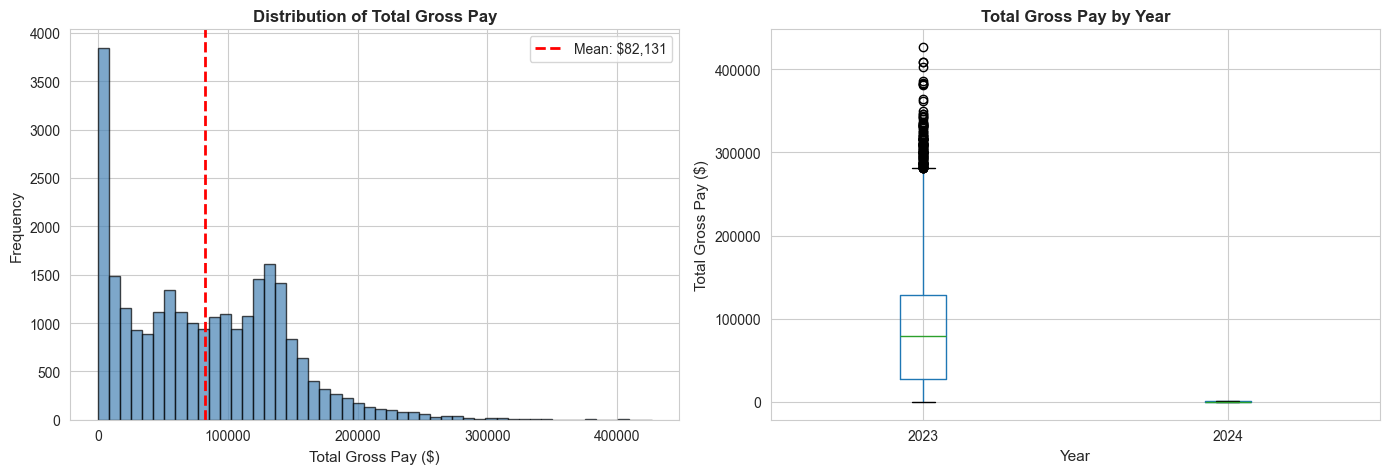

Mean: $82,130.84
Median: $78,360.69


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['TOTAL_GROSS'], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Total Gross Pay ($)', fontsize=11)
axes[0].set_ylabel('Frequency', fontsize=11)
axes[0].set_title('Distribution of Total Gross Pay', fontsize=12, fontweight='bold')
mean_val = df['TOTAL_GROSS'].mean()
axes[0].axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Mean: ${mean_val:,.0f}')
axes[0].legend()

df.boxplot(column='TOTAL_GROSS', by='YEAR', ax=axes[1])
axes[1].set_xlabel('Year', fontsize=11)
axes[1].set_ylabel('Total Gross Pay ($)', fontsize=11)
axes[1].set_title('Total Gross Pay by Year', fontsize=12, fontweight='bold')
plt.suptitle('')

plt.tight_layout()
plt.show()

print(f"Mean: ${df['TOTAL_GROSS'].mean():,.2f}")
print(f"Median: ${df['TOTAL_GROSS'].median():,.2f}")

### 4.2 Pay Trends Across Years

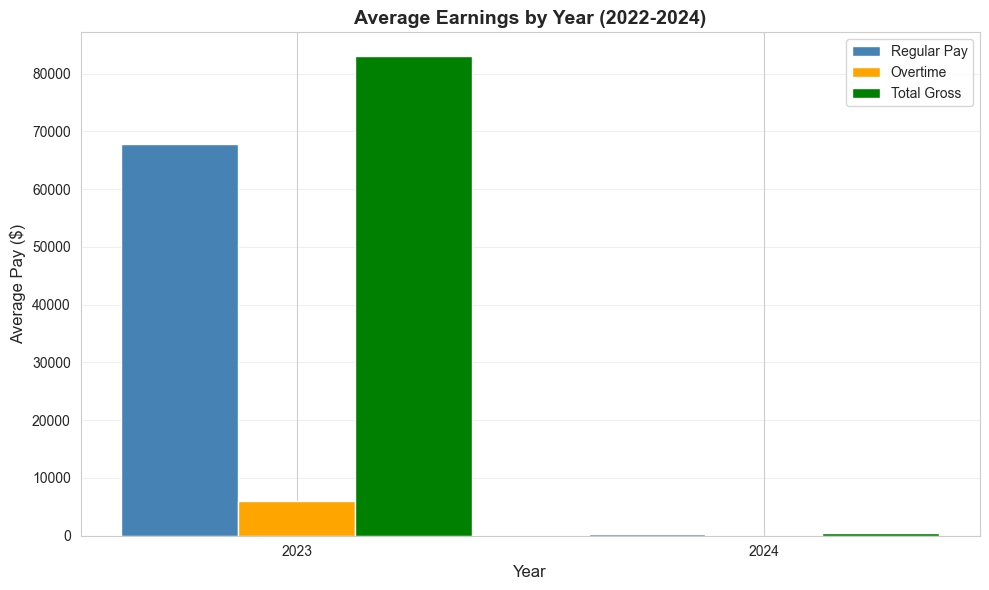

           REGULAR     OVERTIME   TOTAL_GROSS
YEAR                                         
2023  67865.571543  5936.015933  83013.641338
2024    372.383763     1.620789    457.326953


In [7]:
yearly_avg = df.groupby('YEAR')[['REGULAR', 'OVERTIME', 'TOTAL_GROSS']].mean()

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(yearly_avg))
width = 0.25

ax.bar(x - width, yearly_avg['REGULAR'], width, label='Regular Pay', color='steelblue')
ax.bar(x, yearly_avg['OVERTIME'], width, label='Overtime', color='orange')
ax.bar(x + width, yearly_avg['TOTAL_GROSS'], width, label='Total Gross', color='green')

ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Average Pay ($)', fontsize=12)
ax.set_title('Average Earnings by Year (2022-2024)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(yearly_avg.index)
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(yearly_avg)

### 4.3 Top 10 Departments by Average Pay

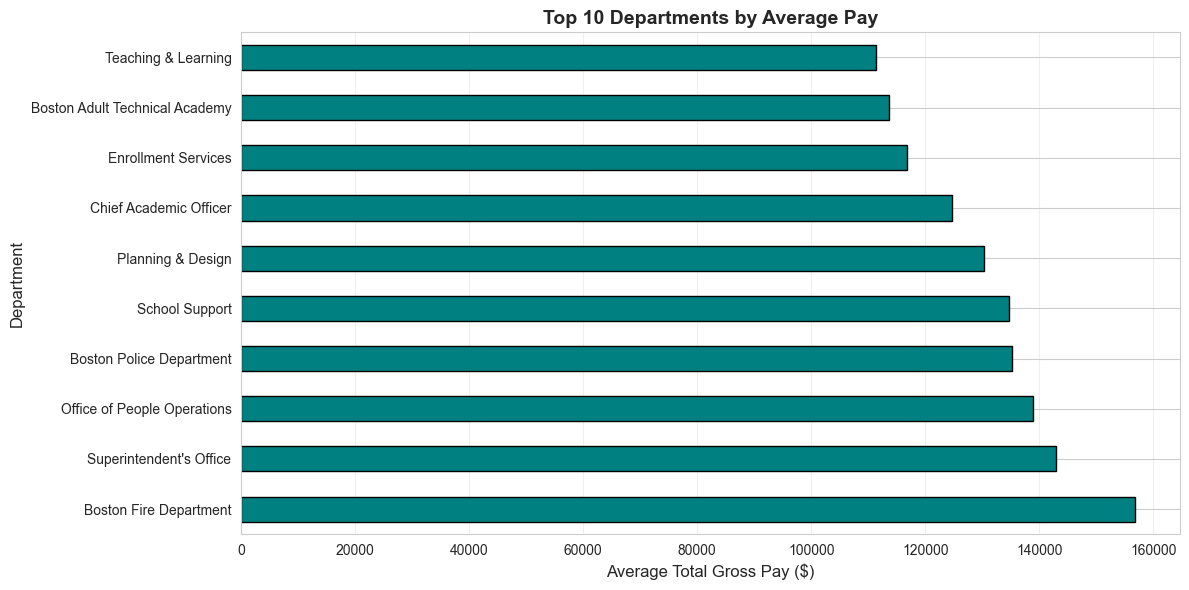


Top 10 Departments:
 1. Boston Fire Department                   $156,842.31
 2. Superintendent's Office                  $143,006.54
 3. Office of People Operations              $138,949.90
 4. Boston Police Department                 $135,185.48
 5. School Support                           $134,750.20
 6. Planning & Design                        $130,266.62
 7. Chief Academic Officer                   $124,725.44
 8. Enrollment Services                      $116,717.97
 9. Boston Adult Technical Academy           $113,613.29
10. Teaching & Learning                      $111,390.79


In [8]:
top_depts = df.groupby('DEPARTMENT_NAME')['TOTAL_GROSS'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))
top_depts.plot(kind='barh', color='teal', edgecolor='black')
plt.xlabel('Average Total Gross Pay ($)', fontsize=12)
plt.ylabel('Department', fontsize=12)
plt.title('Top 10 Departments by Average Pay', fontsize=14, fontweight='bold')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print("\nTop 10 Departments:")
for i, (dept, pay) in enumerate(top_depts.items(), 1):
    print(f"{i:2d}. {dept:40s} ${pay:,.2f}")

### 4.4 Overtime vs Total Pay Relationship

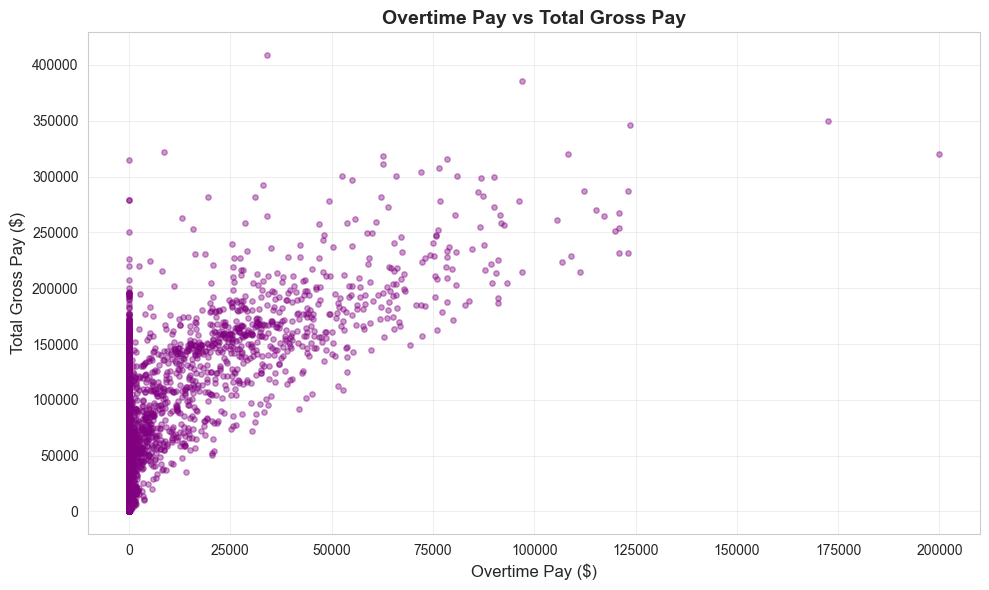


Correlation: 0.5808


In [9]:
sample_df = df.sample(n=min(5000, len(df)), random_state=42)

plt.figure(figsize=(10, 6))
plt.scatter(sample_df['OVERTIME'], sample_df['TOTAL_GROSS'], alpha=0.4, s=15, color='purple')
plt.xlabel('Overtime Pay ($)', fontsize=12)
plt.ylabel('Total Gross Pay ($)', fontsize=12)
plt.title('Overtime Pay vs Total Gross Pay', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

corr = df[['OVERTIME', 'TOTAL_GROSS']].corr().iloc[0, 1]
print(f"\nCorrelation: {corr:.4f}")

### 4.5 Correlation Heatmap

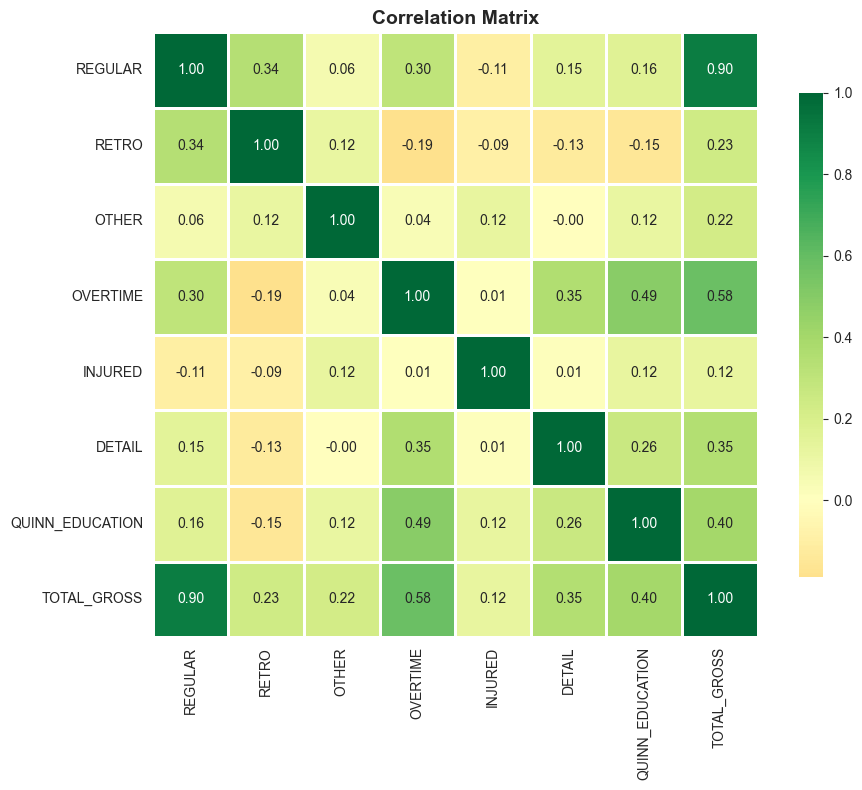

In [10]:
corr_cols = ['REGULAR', 'RETRO', 'OTHER', 'OVERTIME', 'INJURED', 'DETAIL', 'QUINN_EDUCATION', 'TOTAL_GROSS']
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdYlGn', center=0, 
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Predictive Modeling

### 5.1 Data Preparation

In [11]:
df_model = df.copy()

le = LabelEncoder()
df_model['DEPT_ENCODED'] = le.fit_transform(df_model['DEPARTMENT_NAME'])

feature_cols = ['REGULAR', 'OVERTIME', 'RETRO', 'OTHER', 'DEPT_ENCODED', 'YEAR']
X = df_model[feature_cols]
y = df_model['TOTAL_GROSS']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training: {X_train.shape[0]:,} | Test: {X_test.shape[0]:,}")

Training: 20,872 | Test: 5,219


### 5.2 Model 1: Linear Regression

In [12]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

lr_r2 = r2_score(y_test, y_pred_lr)
lr_mae = mean_absolute_error(y_test, y_pred_lr)
lr_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))

print("="*50)
print("LINEAR REGRESSION")
print("="*50)
print(f"R² Score: {lr_r2:.4f}")
print(f"MAE: ${lr_mae:,.2f}")
print(f"RMSE: ${lr_rmse:,.2f}")
print("\nCoefficients:")
for feat, coef in zip(feature_cols, lr_model.coef_):
    print(f"  {feat:15s}: {coef:.4f}")

LINEAR REGRESSION
R² Score: 0.9415
MAE: $6,208.35
RMSE: $14,847.89

Coefficients:
  REGULAR        : 0.9945
  OVERTIME       : 1.2601
  RETRO          : 0.3236
  OTHER          : 1.2472
  DEPT_ENCODED   : -29.4002
  YEAR           : -4249.2212


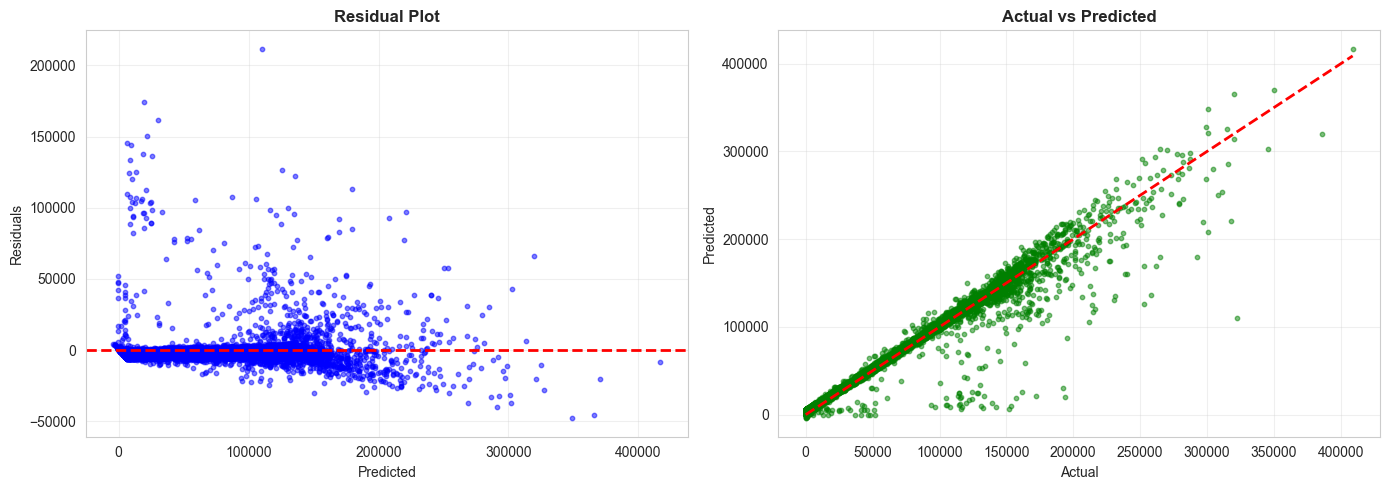

In [13]:
residuals = y_test - y_pred_lr

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_pred_lr, residuals, alpha=0.5, s=10, color='blue')
axes[0].axhline(y=0, color='red', linestyle='--', linewidth=2)
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residual Plot', fontweight='bold')
axes[0].grid(True, alpha=0.3)

axes[1].scatter(y_test, y_pred_lr, alpha=0.5, s=10, color='green')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
axes[1].set_xlabel('Actual')
axes[1].set_ylabel('Predicted')
axes[1].set_title('Actual vs Predicted', fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 5.3 Model 2: Random Forest

In [14]:
rf_model = RandomForestRegressor(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

rf_r2 = r2_score(y_test, y_pred_rf)
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))

print("="*50)
print("RANDOM FOREST")
print("="*50)
print(f"R² Score: {rf_r2:.4f}")
print(f"MAE: ${rf_mae:,.2f}")
print(f"RMSE: ${rf_rmse:,.2f}")

RANDOM FOREST
R² Score: 0.9653
MAE: $3,690.07
RMSE: $11,428.65


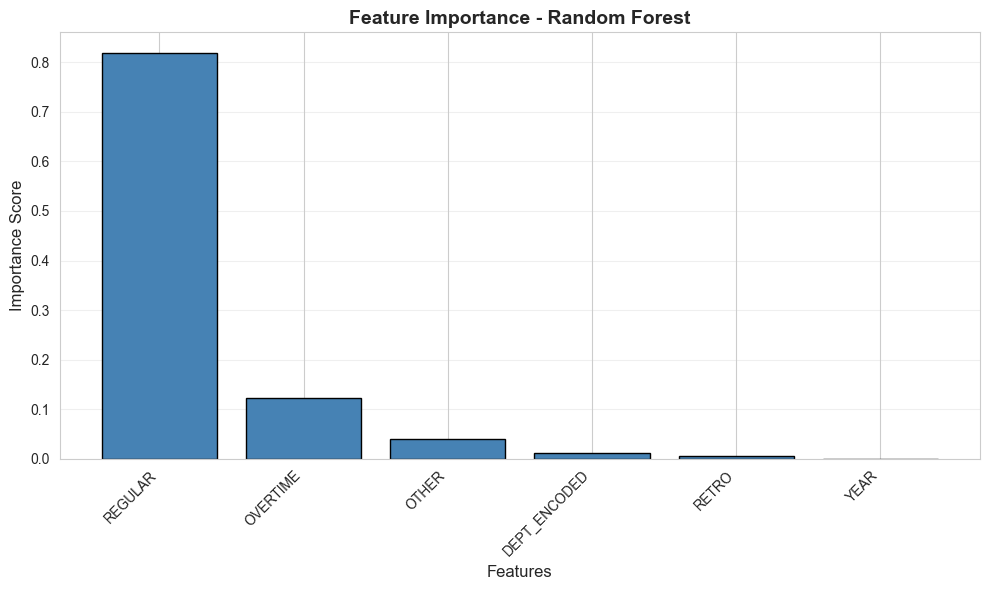


Feature Importance Rankings:
----------------------------------------
 1. REGULAR             : 0.8197
 2. OVERTIME            : 0.1225
 3. OTHER               : 0.0406
 4. DEPT_ENCODED        : 0.0119
 5. RETRO               : 0.0052
 6. YEAR                : 0.0000


In [15]:
plot_feature_importance(rf_model, feature_cols, top_n=6)

### 5.4 Model Comparison


MODEL COMPARISON
            Model       R²         MAE         RMSE
Linear Regression 0.941510 6208.351391 14847.893025
    Random Forest 0.965347 3690.070934 11428.654728

Best: Random Forest


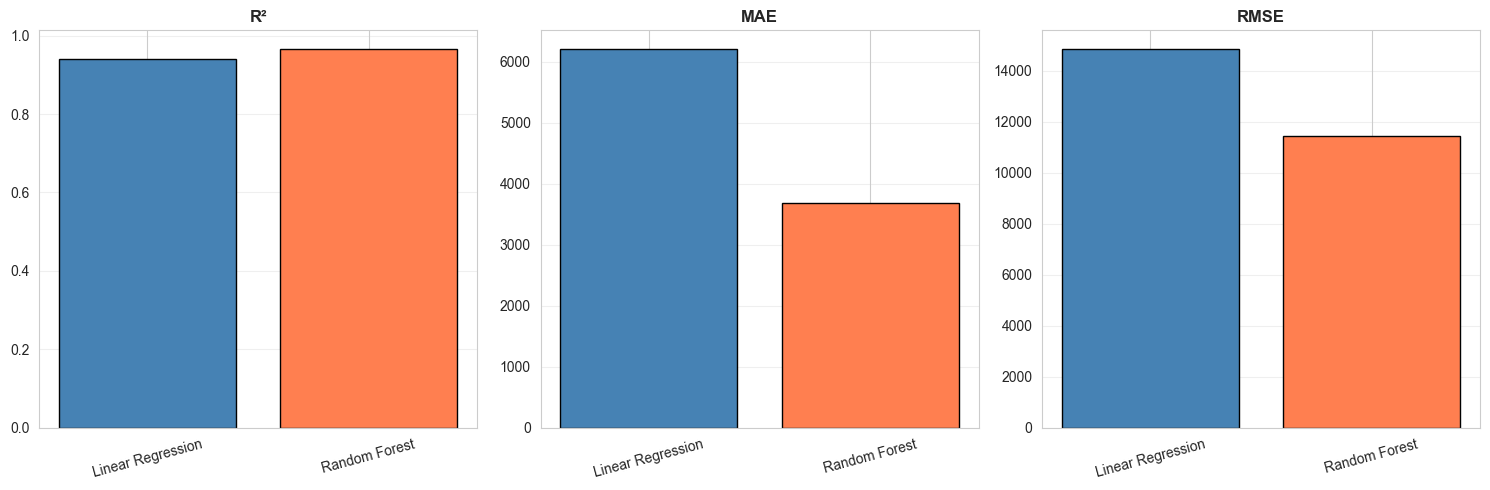

In [16]:
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R²': [lr_r2, rf_r2],
    'MAE': [lr_mae, rf_mae],
    'RMSE': [lr_rmse, rf_rmse]
})

print("\n" + "="*60)
print("MODEL COMPARISON")
print("="*60)
print(comparison.to_string(index=False))
print(f"\nBest: {'Random Forest' if rf_r2 > lr_r2 else 'Linear Regression'}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
colors = ['steelblue', 'coral']

for i, metric in enumerate(['R²', 'MAE', 'RMSE']):
    axes[i].bar(comparison['Model'], comparison[metric], color=colors, edgecolor='black')
    axes[i].set_title(metric, fontweight='bold')
    axes[i].grid(axis='y', alpha=0.3)
    axes[i].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

### 5.5 Model 3: ARIMA Forecasting

In [17]:
ts_total = df.groupby('YEAR')['TOTAL_GROSS'].sum()

print("Time Series Data:")
print("-"*40)
for year, total in ts_total.items():
    print(f"{year}: ${total:,.0f}")

Time Series Data:
----------------------------------------
2023: $2,142,748,110
2024: $127,594


In [18]:
# Note: Only 3 years of data, so ADF test is not applicable
print("\nStationarity Analysis:")
print("-"*40)
print("Note: With only 3 data points (2022-2024),")
print("formal stationarity tests are not meaningful.")
print("Visual inspection shows an upward trend.")

# Calculate simple year-over-year growth
yoy_growth = ts_total.pct_change() * 100
print(f"\nYear-over-Year Growth Rates:")
for year in yoy_growth.index[1:]:
    print(f"  {year}: {yoy_growth[year]:.2f}%")


Stationarity Analysis:
----------------------------------------
Note: With only 3 data points (2022-2024),
formal stationarity tests are not meaningful.
Visual inspection shows an upward trend.

Year-over-Year Growth Rates:
  2024: -99.99%


In [19]:
# Use simpler ARIMA(0,1,0) due to limited data (only 3 points)
arima_model = ARIMA(ts_total, order=(0, 1, 0))
arima_fit = arima_model.fit()

print("\nARIMA(0,1,0) Model Results:")
print("="*50)
print("Note: Using random walk model due to limited data.")
print(f"AIC: {arima_fit.aic:.2f}")
print(f"BIC: {arima_fit.bic:.2f}")


ARIMA(0,1,0) Model Results:
Note: Using random walk model due to limited data.
AIC: 48.12
BIC: 46.12


In [20]:
forecast_2025 = arima_fit.forecast(steps=1)
forecast_conf = arima_fit.get_forecast(steps=1).conf_int()

print("\n" + "="*60)
print("2025 FORECAST")
print("="*60)
print(f"Predicted: ${forecast_2025.values[0]:,.0f}")
print(f"95% CI: ${forecast_conf.iloc[0,0]:,.0f} - ${forecast_conf.iloc[0,1]:,.0f}")

growth = ((forecast_2025.values[0] / ts_total.iloc[-1]) - 1) * 100
print(f"Growth Rate: {growth:.2f}%")


2025 FORECAST
Predicted: $127,594
95% CI: $-2,969,338,373 - $2,969,593,561
Growth Rate: 0.00%


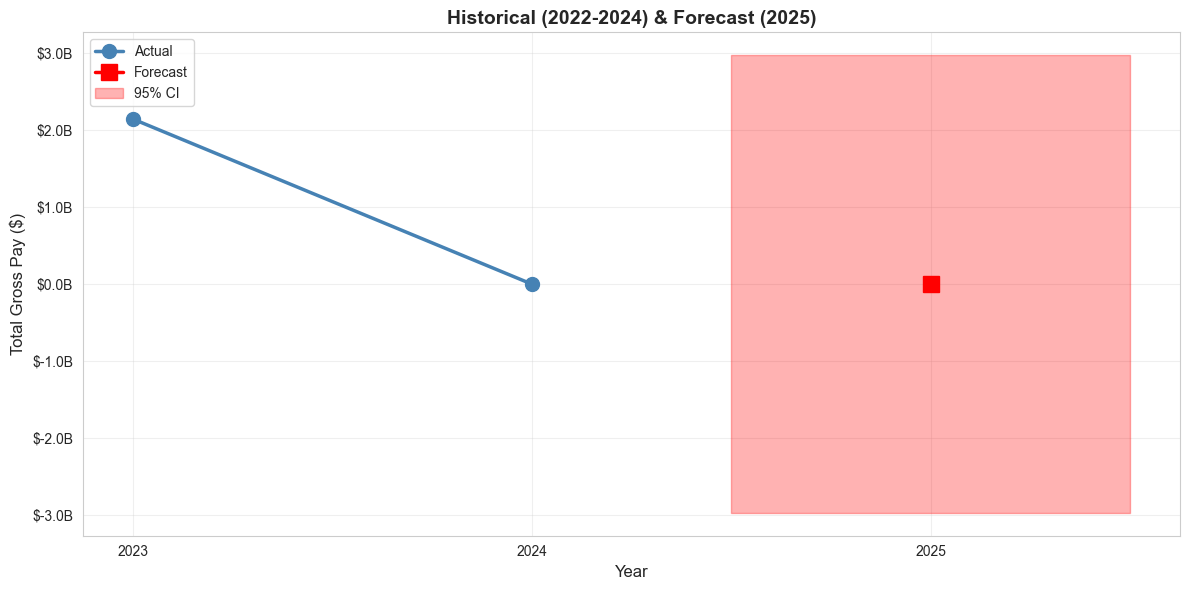

In [21]:
plt.figure(figsize=(12, 6))

years = ts_total.index.tolist()
plt.plot(years, ts_total.values, marker='o', markersize=10, linewidth=2.5, 
         label='Actual', color='steelblue')

plt.plot([2025], forecast_2025.values, marker='s', markersize=12, linewidth=2.5, 
         label='Forecast', color='red')

plt.fill_between([2024.5, 2025.5], 
                 [forecast_conf.iloc[0,0], forecast_conf.iloc[0,0]], 
                 [forecast_conf.iloc[0,1], forecast_conf.iloc[0,1]], 
                 alpha=0.3, color='red', label='95% CI')

plt.xlabel('Year', fontsize=12)
plt.ylabel('Total Gross Pay ($)', fontsize=12)
plt.title('Historical (2022-2024) & Forecast (2025)', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(years + [2025])
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x/1e9:.1f}B'))
plt.tight_layout()
plt.show()

## 6. Key Findings Summary

In [22]:
print("\n" + "="*70)
print("KEY FINDINGS")
print("="*70)

print("\n1. DATASET")
print(f"   Records: {len(df):,}")
print(f"   Avg Pay: ${df['TOTAL_GROSS'].mean():,.2f}")

print("\n2. MODELS")
print(f"   Linear R²: {lr_r2:.4f}")
print(f"   RF R²: {rf_r2:.4f}")
print(f"   Best: {'RF' if rf_r2 > lr_r2 else 'LR'}")

print("\n3. TOP FEATURES")
top_feat = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=False)
for i, (f, imp) in enumerate(top_feat.head(3).items(), 1):
    print(f"   {i}. {f}: {imp:.4f}")

print("\n4. 2025 FORECAST")
print(f"   Predicted: ${forecast_2025.values[0]:,.0f}")
print(f"   Growth: {growth:.2f}%")

print("\n" + "="*70)


KEY FINDINGS

1. DATASET
   Records: 26,091
   Avg Pay: $82,130.84

2. MODELS
   Linear R²: 0.9415
   RF R²: 0.9653
   Best: RF

3. TOP FEATURES
   1. REGULAR: 0.8197
   2. OVERTIME: 0.1225
   3. OTHER: 0.0406

4. 2025 FORECAST
   Predicted: $127,594
   Growth: 0.00%

